In [ ]:
Szybki check do danych z datasetu. Pobierzcie osobno do folderu data/raw. 

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

device_dir = (
    Path.home()
    / "Desktop/ResearchProject1/project/data/raw/Danmini_Doorbell"
)

rows = []

for path in sorted(device_dir.rglob("*.csv")):
    traffic = (
        "Benign"
        if path.name == "benign_traffic.csv"
        else path.parent.name.removesuffix("_attacks").capitalize()
    )

    data = pd.read_csv(path, usecols=[0])

    rows.append({
        "Traffic": traffic,
        "Recording": path.stem,
        "Records": len(data),
    })

recordings = pd.DataFrame(rows)
display(recordings)

,Traffic,Recording,Records
0,Benign,benign_traffic,49548
1,Gafgyt,combo,59718
2,Gafgyt,junk,29068
3,Gafgyt,scan,29849
4,Gafgyt,tcp,92141
5,Gafgyt,udp,105874
6,Mirai,ack,102195
7,Mirai,scan,107685
8,Mirai,syn,122573
9,Mirai,udp,237665


In [ ]:
Wykresik


,Records,Share (%)
Traffic,,
Benign,49548,4.87
Gafgyt,316650,31.10
Mirai,652100,64.04


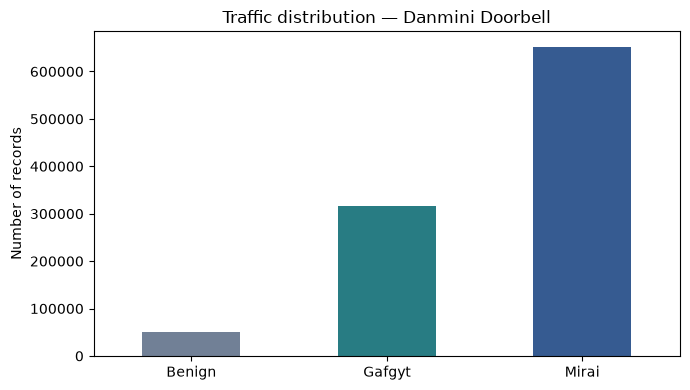

In [2]:
summary = (
    recordings.groupby("Traffic")["Records"]
    .sum()
    .reindex(["Benign", "Gafgyt", "Mirai"])
    .to_frame()
)

summary["Share (%)"] = (
    100 * summary["Records"] / summary["Records"].sum()
).round(2)

display(summary)

summary["Records"].plot.bar(
    color=["#718096", "#287c83", "#365b91"],
    rot=0,
    figsize=(7, 4),
)

plt.title("Traffic distribution — Danmini Doorbell")
plt.xlabel("")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

,Records,Share (%)
Traffic,,
Benign,49548,4.87
Gafgyt,316650,31.10
Mirai,652100,64.04


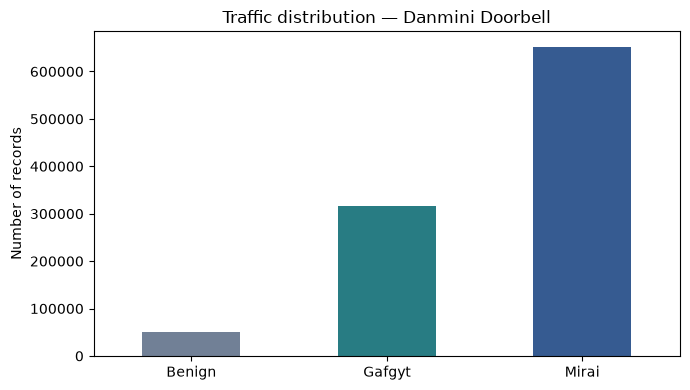

In [11]:
summary = (
    recordings.groupby("Traffic")["Records"]
    .sum()
    .reindex(["Benign", "Gafgyt", "Mirai"])
    .to_frame()
)

summary["Share (%)"] = (
    100 * summary["Records"] / summary["Records"].sum()
).round(2)

display(summary)

summary["Records"].plot.bar(
    color=["#718096", "#287c83", "#365b91"],
    rot=0,
    figsize=(7, 4),
)

plt.title("Traffic distribution — Danmini Doorbell")
plt.xlabel("")
plt.ylabel("Number of records")
plt.tight_layout()
plt.savefig("plot1.png")
plt.show()


In [10]:
# Wyliczenie accuracy

In [3]:
total = summary["Records"].sum()
benign = summary.loc["Benign", "Records"]
attacks = total - benign

print(f"Attack-to-benign ratio: {attacks / benign:.1f}:1")
print(f"Always predicting 'attack' would give {100 * attacks / total:.2f}% accuracy.")
print("False-positive rate = 100%.")

Attack-to-benign ratio: 19.6:1
Always predicting 'attack' would give 95.13% accuracy.
Its false-positive rate would be 100%.
